# 18b - Follow-up: calibrate and set the threshold for the ensemble, to deploy it

**This is a follow-up to notebook 18, added after seeing its results, and reported as such.**

**Why:** in notebook 18 the ensemble (v2 ResNet-50 seed 44 + ConvNeXt-Tiny 1e-4 +
EfficientNet-B0, the members fixed in notebook 13) won D2: its AURC was 0.086 against 0.195
for the single model, with the whole bootstrap range below zero. It was not deployed only
because the backend served one model. That was an engineering limit, not a result: the
backend now averages several models, so the D2 winner is deployed, as D2 itself says.

**Rules, unchanged from notebook 18:** D6 (lowest out-of-sample log-loss among methods
that keep the diagnosis; a tie keeps temperature; the backend applies temperature, so another
winner would be reported and temperature deployed) and D7 as clarified in notebook 13b (the
lowest threshold whose bootstrap lower bound of accuracy on answered photos is at least 90%,
else the cost-based fallback). Nothing else is chosen here.

**How the ensemble is computed (the backend does exactly this):** each model's softmax
probabilities are averaged, the log of the average is divided by the temperature, and a
softmax gives the calibrated probabilities. The crop rule and threshold then apply as before.

Uses the scores notebooks 15 and 17 saved; no GPU needed. About 10 minutes.

In [1]:
from pathlib import Path
import sys

from google.colab import drive

drive.mount("/content/drive")

REPO_URL = "https://github.com/BilliartMuthoni/confidence-calibrated-crop-diagnosis.git"
REPO_DIR = Path("/content/drive/MyDrive/Sproutly-app")

if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}

ML_DIR = REPO_DIR / "ml"
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import config

Mounted at /content/drive


In [2]:
!git -C {REPO_DIR} config core.fileMode false
!git -C {REPO_DIR} pull --ff-only
!git -C {REPO_DIR} status --short --branch

Already up to date.
Refresh index: 100% (400/400), done.
## main...origin/main
 M ml/notebooks/18b_ensemble_deployment.ipynb
?? ml/results/fusion_quick_test/


In [3]:
%pip install -q -r {ML_DIR}/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 378.3/378.3 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 407.8/407.8 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 100.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.7 MB/s eta 0:00:00


## Settings and the saved scores

In [4]:
import importlib
import json
import shutil

import numpy as np
import pandas as pd
import torch

from src import calibration as cal, fusion, metrics, text_encoders, training
for module in (cal, fusion, metrics, text_encoders, training):
    importlib.reload(module)

TARGET, COST_WRONG, FLOOR, BOOTSTRAP = 0.90, 5.0, 0.5, 1000
FOLDS, REPEATS = 5, 3
SEED = config.RANDOM_SEED

N18 = ML_DIR / "results" / "d22_decision" / "decision.json"
decision18 = json.loads(N18.read_text())
MEMBERS = decision18["question_3_ensemble"]["ensemble"]
assert decision18["question_3_ensemble"]["ensemble_better"], "notebook 18 did not find the ensemble better"
assert MEMBERS == ["d17_resnet50_seed44", "d22_convnext_tiny_lr1e-04", "d22_efficientnet_b0"], MEMBERS
FOLDER = {"d17": config.MODELS_DIR / "d17_comparison", "d22": config.MODELS_DIR / "d22_comparison"}
V2 = [f"d17_resnet50_seed{s}" for s in (42, 43, 44)]
V3 = [f"d22_resnet50_seed{s}" for s in (42, 43, 44)]
SINGLE = decision18["deployed"]["model_run"]                       # notebook 18's single model, for comparison
LATE_HEAD = config.MODELS_DIR / "fusion_late_followup" / "late_head.pt"
OUT_DIR = config.MODELS_DIR / "ensemble_deployment"
REPO_RESULTS = ML_DIR / "results" / "ensemble_deployment"
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPO_RESULTS.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EVAL_SETS = ["val", "test", "ood_test", "selection"]
splits = {name: pd.read_csv(config.SPLITS_DIR / f"{name}.csv") for name in EVAL_SETS}
CLASSES = list(config.PLANTVILLAGE_CLASSES)
INDEX = {name: i for i, name in enumerate(CLASSES)}
CLASS_CROPS = np.array([{"Corn_(maize)": "maize", "Tomato": "tomato", "Potato": "potato"}[c.split("___")[0]]
                        for c in CLASSES])
SHORT = {c: c.replace("Corn_(maize)___", "Maize ").replace("___", " ").replace("_", " ").strip() for c in CLASSES}
FIELD_SOURCES = ["fieldplant", "tanzania"]

PARTS = {}
for name in EVAL_SETS:
    labels = splits[name]["class"].map(INDEX)
    keep = labels.notna().to_numpy()
    lab = labels[keep].astype(int).to_numpy()
    PARTS[name] = {"rows": splits[name][keep].reset_index(drop=True), "keep": keep, "labels": lab, "crops": CLASS_CROPS[lab]}
FIELD = {name: PARTS[name]["rows"]["source"].isin(FIELD_SOURCES).to_numpy() for name in ["val", "test"]}

SCORES = {}
for run in ["v1", *V2, *V3, *MEMBERS]:
    folder = FOLDER["d22"] if run.startswith("d22_") else FOLDER["d17"]
    SCORES[run] = {name: np.load(folder / f"{run}__{name}.npy")[PARTS[name]["keep"]] for name in EVAL_SETS}
# The ensemble's scores: log of the members' averaged probabilities (they act as logits).
SCORES["ensemble"] = {name: np.log(np.mean([metrics.softmax(SCORES[m][name]) for m in MEMBERS], axis=0) + 1e-12)
                      for name in EVAL_SETS}
print("Ensemble members:", MEMBERS, "| running on", DEVICE)

Ensemble members: ['d17_resnet50_seed44', 'd22_convnext_tiny_lr1e-04', 'd22_efficientnet_b0'] | running on cpu


In [5]:
def app(probs, name, mask=None):
    crops, labels = PARTS[name]["crops"], PARTS[name]["labels"]
    if mask is not None:
        crops, labels = crops[mask], labels[mask]
    conf, predicted = cal.crop_confidence(probs, CLASS_CROPS, crops)
    return conf, predicted, predicted == labels


def correct(run, name, mask=None):
    lg = SCORES[run][name] if mask is None else SCORES[run][name][mask]
    return app(metrics.softmax(lg), name, mask)[2]

## D6 and D7 for the ensemble

In [6]:
sel = PARTS["selection"]
table = cal.compare(SCORES["ensemble"]["selection"], sel["labels"], folds=FOLDS, repeats=REPEATS, seed=SEED)
METHOD, REASON = cal.choose_method(table)
d6_summary = table.groupby("method").agg(nll=("nll", "mean"), nll_sd=("nll", "std"), ece=("ece", "mean"),
                                         aurc=("aurc", "mean"), changed_predictions=("changed_predictions", "mean"))
display(d6_summary.round(4))
DEPLOY_METHOD = METHOD if METHOD in ("temperature", "none") else "temperature"
print(f"D6: {METHOD} ({REASON}); deployed: {DEPLOY_METHOD}")

oof = cal.out_of_fold(DEPLOY_METHOD, SCORES["ensemble"]["selection"], sel["labels"], FOLDS, SEED)
conf_oof, _, correct_oof = app(oof, "selection")
D7 = cal.choose_threshold_verified(conf_oof, correct_oof, TARGET, COST_WRONG, FLOOR, n=BOOTSTRAP, seed=SEED)
THRESHOLD = D7["threshold"]
D7["answered_at_threshold"] = cal.at_threshold(conf_oof, correct_oof, THRESHOLD)
FINAL = cal.fit(DEPLOY_METHOD, SCORES["ensemble"]["selection"], sel["labels"])
TEMPERATURE = FINAL.params.get("temperature", 1.0)
print(json.dumps(D7, indent=1, default=float))
print(f"\nEnsemble: calibration {DEPLOY_METHOD} (T = {TEMPERATURE:.4f}) | threshold {THRESHOLD:.3f}")

,nll,nll_sd,ece,aurc,changed_predictions
method,,,,,
dirichlet,0.3111,0.0004,0.0205,0.0218,0.3530
histogram,1.5783,0.0010,0.0179,0.2142,0.0000
isotonic,1.5788,0.0007,0.0120,0.2096,0.0000
none,1.8562,0.0000,0.1448,0.2135,0.0000
temperature,1.2932,0.0002,0.0913,0.2046,0.0000
vector,0.5815,0.0002,0.0481,0.0606,0.3431


D6: temperature (lowest out-of-sample log-loss); deployed: temperature
{
 "threshold": 0.5,
 "target_reachable": true,
 "rule": "lowest threshold whose bootstrap lower bound of accuracy on answered photos is >= 90%",
 "original_rule_threshold": 0.5,
 "best_lower_bound": 1.0,
 "threshold_at_best_lower_bound": 0.86,
 "answered_at_threshold": {
  "threshold": 0.5,
  "coverage": 0.4163831457733578,
  "referred": 0.5836168542266422,
  "selective_accuracy": 0.9566310496543055,
  "wrong_and_answered": 0.01805809997382884
 }
}

Ensemble: calibration temperature (T = 2.4381) | threshold 0.500


## Ensemble against the single model of notebook 18, on every set

The single model's numbers are recomputed here the same way (its own calibration from
notebook 18), so the two rows of each set are directly comparable.

In [7]:
single_cal = decision18["deployed"]
single_final = cal.Calibrator("temperature", {"temperature": single_cal["temperature"]})
single_oof = cal.out_of_fold("temperature", SCORES[SINGLE]["selection"], sel["labels"], FOLDS, SEED)


def row(probs, name, threshold, mask=None):
    conf, _, ok = app(probs, name, mask)
    at = cal.at_threshold(conf, ok, threshold)
    return {"photos": len(ok), "accuracy (crop given)": ok.mean(), "ece": metrics.expected_calibration_error(conf, ok),
            "aurc": cal.aurc(conf, ok), "answered": at["coverage"], "accuracy of answered": at["selective_accuracy"],
            "wrong and answered": at["wrong_and_answered"]}


rows = []
for label, name, mask in [("selection (out of fold)", "selection", None), ("test (in-domain)", "test", None),
                          ("test: field photos", "test", FIELD["test"]), ("PlantDoc (out-of-domain)", "ood_test", None)]:
    for model, calibrator, threshold, oof_probs in [(SINGLE, single_final, single_cal["threshold"], single_oof),
                                                    ("ensemble", FINAL, THRESHOLD, oof)]:
        lg = SCORES[model][name] if mask is None else SCORES[model][name][mask]
        probs = oof_probs if name == "selection" else calibrator.probabilities(lg)
        rows.append({"set": label, "model": model, **row(probs, name, threshold, mask)})
compare = pd.DataFrame(rows).set_index(["set", "model"])
display(compare.round(4))

photos  accuracy (crop given)  \
set                      model                                                
selection (out of fold)  d17_resnet50_seed44    3821                 0.6577   
                         ensemble               3821                 0.7459   
test (in-domain)         d17_resnet50_seed44    2441                 0.9963   
                         ensemble               2441                 0.9951   
test: field photos       d17_resnet50_seed44     563                 0.9929   
                         ensemble                563                 0.9893   
PlantDoc (out-of-domain) d17_resnet50_seed44     953                 0.4470   
                         ensemble                953                 0.5593   

                                                 ece    aurc  answered  \
set                      model                                           
selection (out of fold)  d17_resnet50_seed44  0.2275  0.1946    0.1599   
                         ensemble             0.2735  0.0861    0.4164   
test (in-domain)         d17_resnet50_seed44  0.1272  0.0008    0.8382   
                         ensemble             0.0757  0.0010    0.9959   
test: field photos       d17_resnet50_seed44  0.2023  0.0075    0.6412   
                         ensemble             0.1119  0.0078    0.9893   
PlantDoc (out-of-domain) d17_resnet50_seed44  0.1553  0.4926    0.1291   
                         ensemble             0.1781  0.3886    0.3610   

                                              accuracy of answered  \
set                      model                                       
selection (out of fold)  d17_resnet50_seed44                0.9231   
                         ensemble                           0.9566   
test (in-domain)         d17_resnet50_seed44                0.9990   
                         ensemble                           0.9963   
test: field photos       d17_resnet50_seed44                0.9945   
                         ensemble                           0.9910   
PlantDoc (out-of-domain) d17_resnet50_seed44                0.5691   
                         ensemble                           0.6424   

                                              wrong and answered  
set                      model                                    
selection (out of fold)  d17_resnet50_seed44              0.0123  
                         ensemble                         0.0181  
test (in-domain)         d17_resnet50_seed44              0.0008  
                         ensemble                         0.0037  
test: field photos       d17_resnet50_seed44              0.0036  
                         ensemble                         0.0089  
PlantDoc (out-of-domain) d17_resnet50_seed44              0.0556  
                         ensemble                         0.1291

## Where the ensemble gains and loses (reported only)

In [8]:
def per_group(name, by):
    rows = PARTS[name]["rows"].assign(cls=lambda d: d["class"].map(SHORT))
    out = []
    for key, group in rows.groupby(by):
        mask = np.zeros(len(rows), bool)
        mask[group.index.to_numpy()] = True
        entry = dict(zip(by, key if isinstance(key, tuple) else (key,)))
        entry["photos"] = int(mask.sum())
        entry["v1"] = correct("v1", name, mask).mean()
        entry["v2 seed 44"] = correct(SINGLE, name, mask).mean()
        entry["v3 (mean of 3)"] = np.mean([correct(r, name, mask).mean() for r in V3])
        entry["ensemble"] = correct("ensemble", name, mask).mean()
        entry["ensemble vs v1"] = entry["ensemble"] - entry["v1"]
        out.append(entry)
    return pd.DataFrame(out).set_index(by)


selection_by_source_class = per_group("selection", ["source", "cls"])
plantdoc_by_class = per_group("ood_test", ["cls"])
test_by_class = per_group("test", ["cls"])
for title, t in [("Selection set by source and class", selection_by_source_class),
                 ("Test set by class", test_by_class), ("PlantDoc by class (reported only)", plantdoc_by_class)]:
    print(title)
    display(t.round(3))

Selection set by source and class


photos     v1  \
source          cls                                                        
maize_jhenaidah Maize Cercospora leaf spot Gray leaf spot     554  0.733   
                Maize healthy                                 359  0.994   
maize_natore    Maize Cercospora leaf spot Gray leaf spot     826  0.460   
                Maize Common rust                             126  0.444   
                Maize healthy                                 602  0.869   
potato_holeta   Potato Late blight                             67  0.985   
                Potato healthy                                344  0.817   
tomato_bd       Tomato Bacterial spot                          97  0.000   
                Tomato Early blight                           447  0.098   
                Tomato Late blight                             92  0.848   
                Tomato healthy                                307  0.013   

                                                           v2 seed 44  \
source          cls                                                     
maize_jhenaidah Maize Cercospora leaf spot Gray leaf spot       0.688   
                Maize healthy                                   0.994   
maize_natore    Maize Cercospora leaf spot Gray leaf spot       0.508   
                Maize Common rust                               0.151   
                Maize healthy                                   0.927   
potato_holeta   Potato Late blight                              1.000   
                Potato healthy                                  0.988   
tomato_bd       Tomato Bacterial spot                           0.000   
                Tomato Early blight                             0.568   
                Tomato Late blight                              0.489   
                Tomato healthy                                  0.235   

                                                           v3 (mean of 3)  \
source          cls                                                         
maize_jhenaidah Maize Cercospora leaf spot Gray leaf spot           0.647   
                Maize healthy                                       0.993   
maize_natore    Maize Cercospora leaf spot Gray leaf spot           0.586   
                Maize Common rust                                   0.844   
                Maize healthy                                       0.888   
potato_holeta   Potato Late blight                                  0.995   
                Potato healthy                                      0.995   
tomato_bd       Tomato Bacterial spot                               0.031   
                Tomato Early blight                                 0.429   
                Tomato Late blight                                  0.525   
                Tomato healthy                                      0.166   

                                                           ensemble  \
source          cls                                                   
maize_jhenaidah Maize Cercospora leaf spot Gray leaf spot     0.755   
                Maize healthy                                 0.994   
maize_natore    Maize Cercospora leaf spot Gray leaf spot     0.747   
                Maize Common rust                             0.913   
                Maize healthy                                 0.919   
potato_holeta   Potato Late blight                            1.000   
                Potato healthy                                0.994   
tomato_bd       Tomato Bacterial spot                         0.247   
                Tomato Early blight                           0.485   
                Tomato Late blight                            0.457   
                Tomato healthy                                0.319   

                                                           ensemble vs v1  
source          cls                                                        
maize_jhenaidah Maize Cercospora leaf spot

Test set by class


,photos,v1,v2 seed 44,v3 (mean of 3),ensemble,ensemble vs v1
cls,,,,,,
Maize Cercospora leaf spot Gray leaf spot,93,0.978,0.957,0.903,0.946,-0.032
Maize Common rust,176,1.000,1.000,1.000,1.000,0.000
Maize Northern Leaf Blight,150,0.993,1.000,0.996,1.000,0.007
Maize healthy,201,1.000,1.000,1.000,1.000,0.000
Potato Early blight,279,0.996,1.000,0.996,1.000,0.004
Potato Late blight,297,0.993,0.997,0.994,0.997,0.003
Potato healthy,169,1.000,1.000,1.000,1.000,0.000
Tomato Bacterial spot,304,1.000,1.000,1.000,1.000,0.000
Tomato Early blight,160,0.981,0.994,0.981,0.981,0.000


PlantDoc by class (reported only)


,photos,v1,v2 seed 44,v3 (mean of 3),ensemble,ensemble vs v1
cls,,,,,,
Maize Cercospora leaf spot Gray leaf spot,65,0.846,0.877,0.779,0.954,0.108
Maize Common rust,116,0.224,0.362,0.626,0.672,0.448
Maize Northern Leaf Blight,189,0.190,0.148,0.437,0.354,0.164
Potato Early blight,112,0.500,0.375,0.381,0.366,-0.134
Potato Late blight,100,0.700,0.730,0.763,0.740,0.040
Tomato Bacterial spot,109,0.028,0.092,0.116,0.165,0.138
Tomato Early blight,88,0.216,0.523,0.561,0.568,0.352
Tomato Late blight,111,0.973,0.829,0.739,0.892,-0.081
Tomato healthy,63,0.095,0.571,0.598,0.698,0.603


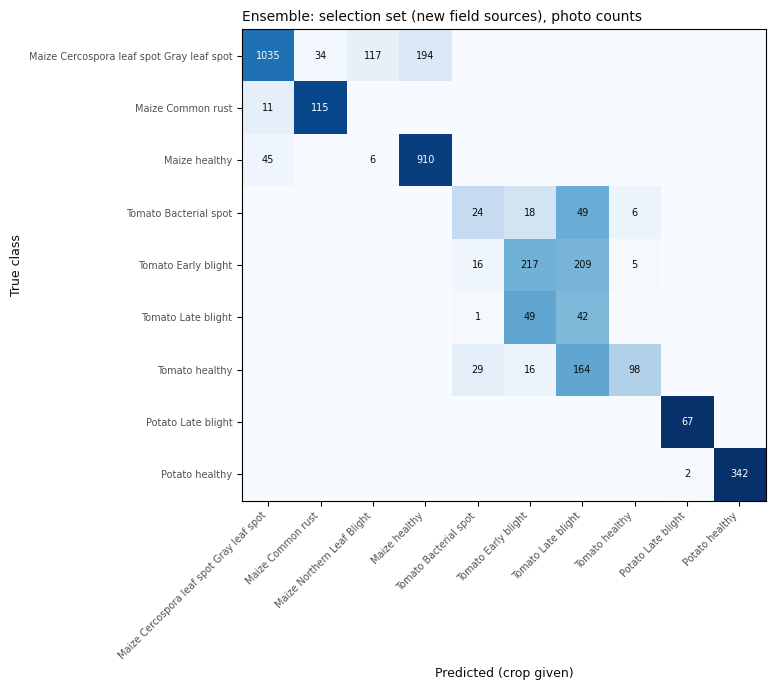

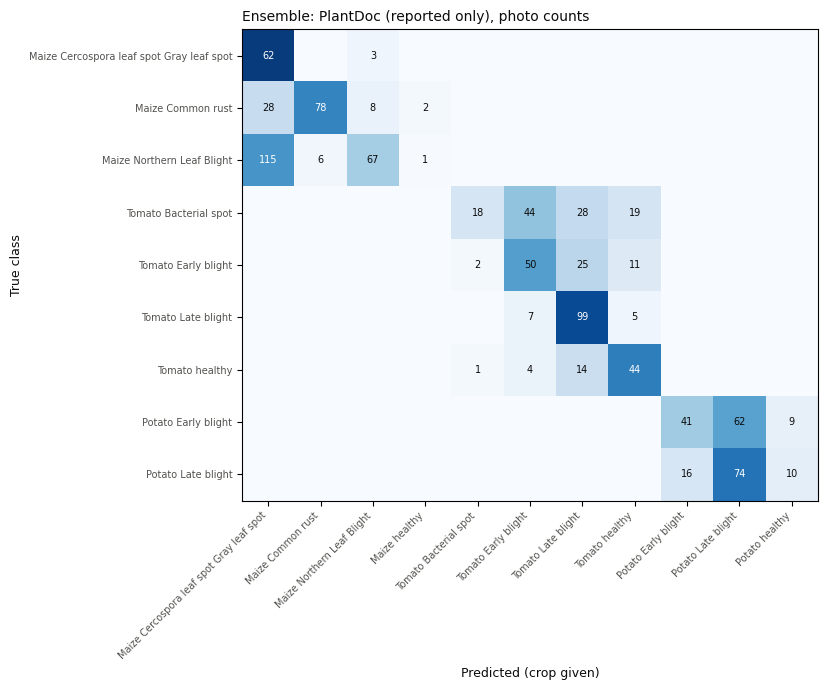

In [9]:
import matplotlib.pyplot as plt

INK, MUTED = "#0b0b0b", "#52514e"


def confusion(name, title, file):
    _, predicted, _ = app(metrics.softmax(SCORES["ensemble"][name]), name)
    labels = PARTS[name]["labels"]
    present = sorted(set(labels) | set(predicted))
    names = [SHORT[CLASSES[i]] for i in present]
    matrix = pd.crosstab(pd.Series([SHORT[CLASSES[i]] for i in labels], name="true class"),
                         pd.Series([SHORT[CLASSES[i]] for i in predicted], name="predicted (crop given)"))
    matrix = matrix.reindex(index=[n for n in names if n in matrix.index], columns=names, fill_value=0)
    shares = matrix.div(matrix.sum(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(shares.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    for i in range(shares.shape[0]):
        for j in range(shares.shape[1]):
            if matrix.iat[i, j]:
                ax.text(j, i, matrix.iat[i, j], ha="center", va="center", fontsize=7,
                        color="white" if shares.iat[i, j] > 0.6 else INK)
    ax.set_xticks(range(len(shares.columns)), shares.columns, rotation=45, ha="right", fontsize=7, color=MUTED)
    ax.set_yticks(range(len(shares.index)), shares.index, fontsize=7, color=MUTED)
    ax.set_xlabel("Predicted (crop given)", color=INK, fontsize=9)
    ax.set_ylabel("True class", color=INK, fontsize=9)
    ax.set_title(title, color=INK, fontsize=10, loc="left")
    plt.tight_layout()
    plt.savefig(OUT_DIR / file, dpi=150)
    plt.show()
    matrix.to_csv(OUT_DIR / file.replace(".png", ".csv"))


confusion("selection", "Ensemble: selection set (new field sources), photo counts", "confusion_selection.png")
confusion("ood_test", "Ensemble: PlantDoc (reported only), photo counts", "confusion_plantdoc.png")

## Late fusion with the BERT text classifier, on the ensemble

In [10]:
descriptions = pd.read_csv(ML_DIR / "data" / "symptoms" / "descriptions.csv", encoding="utf-8-sig")
descriptions = descriptions[descriptions["keep"] == "y"].reset_index(drop=True)
vectors = text_encoders.encode("bert_base", descriptions["text"].tolist(),
                               descriptions.loc[descriptions["split"] == "train", "text"].tolist(), DEVICE)
test_bank = fusion.TextBank.build(descriptions, vectors, CLASSES, "test")
head = fusion.TextClassifier(vectors.shape[1], int((~fusion.healthy_mask(CLASSES)).sum()))
head.load_state_dict(torch.load(LATE_HEAD, map_location="cpu"))
head.to(DEVICE).eval()


def features(model, name, mask=None):
    lg = SCORES[model][name] if mask is None else SCORES[model][name][mask]
    labels = PARTS[name]["labels"] if mask is None else PARTS[name]["labels"][mask]
    return fusion.Features(np.zeros((len(labels), 1), np.float32), lg, labels)


fusion_rows = []
for label, name, mask in [("test", "test", None), ("test: field", "test", FIELD["test"]), ("PlantDoc", "ood_test", None)]:
    part = features("ensemble", name, mask)
    fused = fusion.predict("late", head, part, *test_bank.fixed(part.labels), CLASSES, DEVICE)
    fusion_rows.append({"set": label, "condition": "ensemble alone", **metrics.summarise(part.logits, part.labels, len(CLASSES))})
    fusion_rows.append({"set": label, "condition": "late fusion, with test text", **metrics.summarise(fused, part.labels, len(CLASSES))})
fusion_table = pd.DataFrame(fusion_rows).set_index(["set", "condition"])
display(fusion_table.round(4))
FUSION_BIAS = fusion.bias_tests("late", head, features("ensemble", "test", FIELD["test"]), test_bank, CLASSES, DEVICE)
display(pd.Series(FUSION_BIAS).round(3))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


images  accuracy  macro_f1     ece  \
set         condition                                                         
test        ensemble alone                 2441    0.9951    0.9935  0.0030   
            late fusion, with test text    2441    0.9930    0.9935  0.0047   
test: field ensemble alone                  563    0.9893    0.9813  0.0083   
            late fusion, with test text     563    0.9893    0.9877  0.0095   
PlantDoc    ensemble alone                  953    0.4376    0.4214  0.2914   
            late fusion, with test text     953    0.3872    0.3596  0.3685   

                                            nll  mean_confidence  
set         condition                                             
test        ensemble alone               0.0206           0.9930  
            late fusion, with test text  0.0315           0.9917  
test: field ensemble alone               0.0574           0.9859  
            late fusion, with test text  0.0514           0.9851  
PlantDoc    ensemble alone               2.4719           0.7280  
            late fusion, with test text  2.9239           0.7557

,0
healthy_with_disease_text,0.009
healthy_with_same_crop_text,0.009
healthy_without_text,0.009
diseased_without_text_called_healthy,0.003
diseased_called_healthy_by_resnet_alone,0.003


## Save the decision and the backend settings

In [11]:
calibrator = {"model_runs": MEMBERS, "model_version": "ensemble-v2r44-cnx-effb0",
              "combination": "mean of the members' softmax probabilities; log; divided by the temperature; softmax",
              "method": DEPLOY_METHOD, "temperature": TEMPERATURE, "threshold": THRESHOLD, "rule": D7["rule"],
              "fitted_on": f"selection set ({len(sel['labels'])} photos)",
              "confidence": "best class of the farmer's crop, 11-class probability, not rescaled"}
training.save_json(calibrator, OUT_DIR / "calibrator_final.json")
training.save_json({"why": "D2 winner in notebook 18; the backend's one-model limit was lifted", "D6": {"method": METHOD,
                    "reason": REASON}, "deployed_method": DEPLOY_METHOD, "D7": D7, "fusion_bias": FUSION_BIAS,
                    "deployed": calibrator, "post_hoc_followup": True}, OUT_DIR / "decision.json")
d6_summary.to_csv(OUT_DIR / "d6_methods.csv")
compare.to_csv(OUT_DIR / "ensemble_vs_single.csv")
selection_by_source_class.to_csv(OUT_DIR / "selection_by_source_class.csv")
test_by_class.to_csv(OUT_DIR / "test_by_class.csv")
plantdoc_by_class.to_csv(OUT_DIR / "plantdoc_by_class.csv")
fusion_table.to_csv(OUT_DIR / "late_fusion.csv")

print("Backend settings for the ensemble (put them in the backend's environment, not in Git):")
print("  ML_MODEL_PATH        = " + ",".join(f"models/{m}/model.pt" for m in MEMBERS))
print(f"  TEMPERATURE          = {TEMPERATURE:.4f}")
print(f"  CONFIDENCE_THRESHOLD = {THRESHOLD:.3f}")
print("  Copy each model.pt from Drive: " + ", ".join(f"CropDiseaseDiagnosis/models/{m}/" for m in MEMBERS))

Backend settings for the ensemble (put them in the backend's environment, not in Git):
  ML_MODEL_PATH        = models/d17_resnet50_seed44/model.pt,models/d22_convnext_tiny_lr1e-04/model.pt,models/d22_efficientnet_b0/model.pt
  TEMPERATURE          = 2.4381
  CONFIDENCE_THRESHOLD = 0.500
  Copy each model.pt from Drive: CropDiseaseDiagnosis/models/d17_resnet50_seed44/, CropDiseaseDiagnosis/models/d22_convnext_tiny_lr1e-04/, CropDiseaseDiagnosis/models/d22_efficientnet_b0/


## Copy the results into the repository, sync Drive, save to GitHub

Save the notebook first (Ctrl+S).

In [12]:
for file in OUT_DIR.glob("*"):
    if file.suffix in {".csv", ".json", ".png"}:
        shutil.copy(file, REPO_RESULTS / file.name)
print(sorted(p.name for p in REPO_RESULTS.iterdir()))
drive.flush_and_unmount()
drive.mount("/content/drive")

['calibrator_final.json', 'confusion_plantdoc.csv', 'confusion_plantdoc.png', 'confusion_selection.csv', 'confusion_selection.png', 'd6_methods.csv', 'decision.json', 'ensemble_vs_single.csv', 'late_fusion.csv', 'plantdoc_by_class.csv', 'selection_by_source_class.csv', 'test_by_class.csv']
Mounted at /content/drive


In [13]:
from google.colab import userdata

from src import github_sync

shutil.copy(ML_DIR / "notebooks" / "18b_ensemble_deployment.ipynb", REPO_RESULTS / "notebook.ipynb")
print(github_sync.push(
    REPO_DIR,
    branch="colab/ensemble-deployment",
    message="Follow-up: calibration and threshold for the ensemble, to deploy it",
    token=userdata.get("GITHUB_TOKEN"),
    name="BilliartMuthoni",
    email=userdata.get("GIT_EMAIL"),
    paths=[str(REPO_RESULTS.relative_to(REPO_DIR))],
))

TimeoutException: Requesting secret GITHUB_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.